# Mining comparison on AIT-ADS (plan 7.6, temporal arm)

Same question as notebook 06 (does the mining principle matter?), now on data with an alert order to mine, so all
five methods run:

|  | Label used **after** the search | Label used **during** the search |
|---|---|---|
| **Atemporal** | Eclat | Contrast tree (ours), RIPPER |
| **Temporal** | PrefixSpan | MCTSExtent |

**Protocol: leave-one-scenario-out (LOSO).** Each of the 8 folds trains on the other 7 scenarios (cscas_grouping,
token arm T2) and tests on the held-out scenario's whole timeline. Temporal methods mine per-host look-back
sequences (10 min, 1-min buckets). Same shared treatment as CSCAS: precision gate (benign side relaxed to ≤ π),
condition + near-duplicate dedupe, budget K = 60 per class, class-weighted RF at 0.5, 5 seeds (RIPPER and
MCTSExtent re-mined per seed).

**Read with the label noise in mind.** AIT-ADS labels everything inside an attack time window as an attack, so
F1 and precision stay low for every arm (FINDINGS.md). Compare on PR-AUC and the helps/hurts counts.

Logic: `thesis.system_eval.mining_comparison`; run with `shell-scripts/paper/run_mining_comparison_ait_ads.sh` (DGX).

In [1]:
from __future__ import annotations

import json
import re
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from thesis.paths import ROOT
from thesis.system_eval import mining_comparison as mc

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

ARMS = ["mctsextent", "prefixspan", "ripper", "contrast_tree", "eclat", "none"]
METHODS = [a for a in ARMS if a != "none"]
LABEL = {"mctsextent": "MCTSExtent", "prefixspan": "PrefixSpan", "ripper": "RIPPER",
         "contrast_tree": "Contrast tree", "eclat": "Eclat", "none": "No mining"}
COLOR = {"mctsextent": "tab:purple", "prefixspan": "tab:red", "ripper": "tab:green",
         "contrast_tree": "tab:blue", "eclat": "tab:orange", "none": "tab:gray"}


def to_booktabs(df: pd.DataFrame, caption: str, label: str, float_fmt: str = "{:.3f}") -> str:
    styler = df.style.hide(axis="index").format(
        {c: float_fmt for c in df.select_dtypes("float").columns}
    ).format_index(escape="latex", axis=1).format(escape="latex-math", subset=df.select_dtypes("object").columns)
    return styler.to_latex(hrules=True, caption=caption, label=label, position="t", position_float="centering")

## Load

In [2]:
RUN_DIR = None  # None -> latest full LOSO run (most folds), else a path


def _latest_full_run() -> Path:
    base = ROOT / "artifacts" / "experiments" / "mining_comparison_ait_ads"
    runs = [d for d in sorted(base.glob("*")) if (d / "summary.csv").exists()]
    if not runs:
        raise FileNotFoundError(f"no finished run under {base}")
    n_folds = {d: pd.read_csv(d / "per_step_results.csv")["scenario"].nunique() for d in runs}
    best = max(n_folds.values())
    return [d for d in runs if n_folds[d] == best][-1]


run_dir = Path(RUN_DIR) if RUN_DIR else _latest_full_run()
per_step = pd.read_csv(run_dir / "per_step_results.csv")
features = pd.read_csv(run_dir / "features.csv")
windows = pd.read_csv(run_dir / "windows.csv")
means = mc.per_step_means(per_step)  # seed-averaged, one row per (arm, fold)
FOLD = per_step.groupby("step_i")["scenario"].first().rename("held-out")  # step_i -> scenario
print(run_dir)
print("folds:", list(FOLD), "| rows per arm:", per_step.groupby("arm").size().to_dict(),
      "| seeds:", sorted(per_step["seed"].unique()))

/Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/mining_comparison_ait_ads/20261118_193837
folds: ['fox', 'harrison', 'russellmitchell', 'santos', 'shaw', 'wardbeck', 'wheeler', 'wilson'] | rows per arm: {'contrast_tree': 40, 'eclat': 40, 'mctsextent': 40, 'none': 40, 'prefixspan': 40, 'ripper': 40} | seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


### The folds

Training pools the other 7 scenarios; the test window is the held-out scenario's whole timeline.

In [3]:
folds = windows.assign(test_attack_rate=windows["n_test_attack"] / windows["n_test"])[
    ["scenario", "n_train", "n_train_attack", "n_test", "n_test_attack", "test_attack_rate", "test_days"]
]
folds.round(3)

,scenario,n_train,n_train_attack,n_test,n_test_attack,test_attack_rate,test_days
0,fox,78933,2075,6092,266,0.044,4.997
1,harrison,69020,1614,16005,727,0.045,5.000
2,russellmitchell,80525,2143,4500,198,0.044,3.985
3,santos,73982,2110,11043,231,0.021,3.994
4,shaw,78646,2247,6379,94,0.015,5.980
5,wardbeck,76951,2180,8074,161,0.020,5.000
6,wheeler,67243,2110,17782,231,0.013,4.996
7,wilson,69875,1908,15150,433,0.029,5.993


## §1 Main table

Mean (± std over folds) of the seed-averaged metrics. `mine_seconds` is the whole mine → gate → dedupe step per
seed (the miner alone: `miner_seconds`). Redundancy = share of gated distinct conditions dropped as
near-duplicates. Recall on unseen signatures is not defined here: every held-out attack's alert name is an attack
in some other scenario.

In [4]:
summary = mc.summarize_comparison(per_step).set_index("arm")
main = pd.DataFrame({
    "PR-AUC": summary["pr_auc_mean"], "PR-AUC sd": summary["pr_auc_std"],
    "F1": summary["f1_mean"], "Precision": summary["precision_mean"], "Recall": summary["recall_mean"],
    "ROC-AUC": summary["auc_mean"], "FP/day": summary["fp_per_day_mean"],
    "Features": summary["n_symbolic_mean"], "Cond./feat.": summary["mean_conditions_mean"],
    "Overlap": summary["overlap_mean"], "Redundancy": summary["redundancy_share_mean"],
    "Mine s": summary["mine_seconds_mean"],
}).reindex(ARMS)
main

,PR-AUC,PR-AUC sd,F1,Precision,Recall,ROC-AUC,FP/day,Features,Cond./feat.,Overlap,Redundancy,Mine s
arm,,,,,,,,,,,,
mctsextent,0.307978,0.148476,0.139048,0.087460,0.446051,0.701849,257.814962,48.200,2.785856,0.136777,0.000000,684.03425
prefixspan,0.162771,0.111872,0.098355,0.060998,0.325855,0.641100,300.224480,60.000,2.970833,0.200898,0.975095,123.66375
ripper,0.177025,0.099196,0.083979,0.048775,0.415387,0.651087,463.573009,29.450,4.212747,0.014686,0.005773,101.54525
contrast_tree,0.146813,0.081773,0.078874,0.044969,0.417604,0.642636,492.487372,20.750,2.203413,0.097539,0.615919,2.71750
eclat,0.140035,0.080140,0.079094,0.045216,0.397523,0.635838,473.227333,13.125,2.831729,0.099891,0.748677,4.56375
none,0.067421,0.034961,0.068091,0.038360,0.393466,0.583501,567.049926,0.000,NaN,NaN,NaN,NaN


In [5]:
latex_main = main.reset_index().rename(columns={"arm": "Method"}).assign(Method=lambda d: d["Method"].map(LABEL))
print(to_booktabs(
    latex_main[["Method", "PR-AUC", "F1", "Precision", "Recall", "FP/day", "Features", "Cond./feat.",
                "Redundancy", "Mine s"]],
    caption="Mining comparison on AIT-ADS: leave-one-scenario-out means over 8 folds and 5 seeds "
            "(K = 60, class-weighted RF).",
    label="tab:mining-comparison-ait-ads",
))

\begin{table}[t]
\centering
\caption{Mining comparison on AIT-ADS: leave-one-scenario-out means over 8 folds and 5 seeds (K = 60, class-weighted RF).}
\label{tab:mining-comparison-ait-ads}
\begin{tabular}{lrrrrrrrrr}
\toprule
Method & PR-AUC & F1 & Precision & Recall & FP/day & Features & Cond./feat. & Redundancy & Mine s \\
\midrule
MCTSExtent & 0.308 & 0.139 & 0.087 & 0.446 & 257.815 & 48.200 & 2.786 & 0.000 & 684.034 \\
PrefixSpan & 0.163 & 0.098 & 0.061 & 0.326 & 300.224 & 60.000 & 2.971 & 0.975 & 123.664 \\
RIPPER & 0.177 & 0.084 & 0.049 & 0.415 & 463.573 & 29.450 & 4.213 & 0.006 & 101.545 \\
Contrast tree & 0.147 & 0.079 & 0.045 & 0.418 & 492.487 & 20.750 & 2.203 & 0.616 & 2.717 \\
Eclat & 0.140 & 0.079 & 0.045 & 0.398 & 473.227 & 13.125 & 2.832 & 0.749 & 4.564 \\
No mining & 0.067 & 0.068 & 0.038 & 0.393 & 567.050 & 0.000 & nan & nan & nan \\
\bottomrule
\end{tabular}
\end{table}



## §2 Per fold

Seed-averaged PR-AUC per held-out scenario, and the gain over `none`. Helps/hurts counts as in notebook 06.

In [6]:
pr = means.pivot(index="step_i", columns="arm", values="pr_auc").rename(index=FOLD)[ARMS]
pr.index.name, pr.columns.name = "held-out", None
pr.round(3)

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none
held-out,,,,,,
fox,0.465,0.310,0.292,0.253,0.245,0.089
harrison,0.221,0.174,0.172,0.167,0.163,0.095
russellmitchell,0.081,0.037,0.038,0.034,0.035,0.033
santos,0.302,0.123,0.243,0.179,0.152,0.111
shaw,0.175,0.012,0.014,0.014,0.013,0.012
wardbeck,0.300,0.117,0.207,0.155,0.141,0.042
wheeler,0.517,0.303,0.229,0.201,0.216,0.090
wilson,0.403,0.227,0.221,0.171,0.156,0.067


In [7]:
hh = pd.concat([mc.helps_hurts(per_step, m) for m in ("pr_auc", "f1")], ignore_index=True)
hh

,arm,metric,n_steps,mean_delta,median_delta,helps,hurts,ties
0,contrast_tree,pr_auc,8,0.079391,0.087845,8,0,0
1,eclat,pr_auc,8,0.072614,0.078374,8,0,0
2,mctsextent,pr_auc,8,0.240556,0.224127,8,0,0
3,prefixspan,pr_auc,8,0.095349,0.077068,8,0,0
4,ripper,pr_auc,8,0.109604,0.135393,8,0,0
5,contrast_tree,f1,8,0.010783,0.012429,7,1,0
6,eclat,f1,8,0.011003,0.007468,6,2,0
7,mctsextent,f1,8,0.070957,0.079750,8,0,0
8,prefixspan,f1,8,0.030264,0.032271,7,1,0
9,ripper,f1,8,0.015888,0.016093,8,0,0


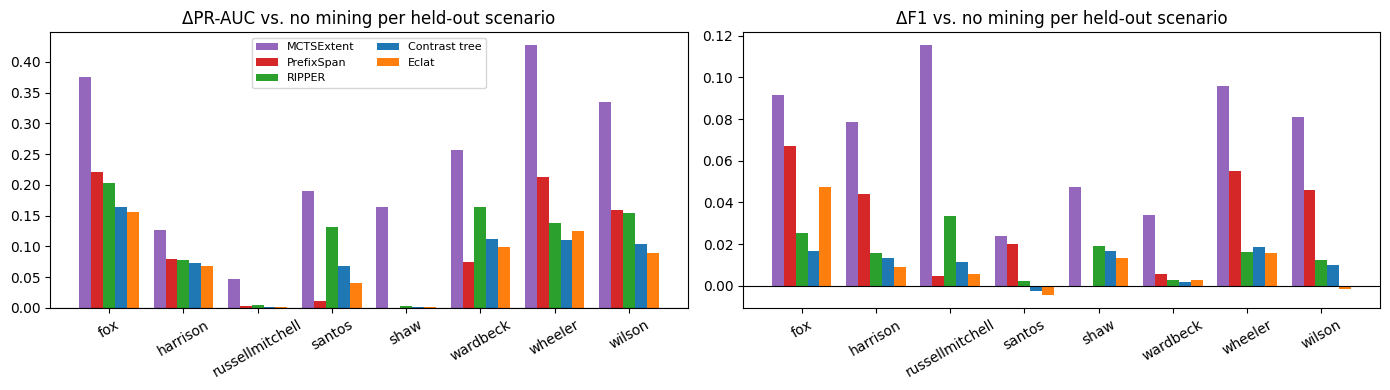

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(pr))
w = 0.16
for ax, m in zip(axes, ("pr_auc", "f1")):
    d = means.pivot(index="step_i", columns="arm", values=m).rename(index=FOLD)
    for j, a in enumerate(METHODS):
        ax.bar(x + (j - 2) * w, d[a] - d["none"], width=w, color=COLOR[a], label=LABEL[a])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x, d.index, rotation=30)
    ax.set_title(f"Δ{m.upper().replace('_', '-')} vs. no mining per held-out scenario")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout()

## §3 Friedman test + Nemenyi critical difference

Folds are the blocks (seed-averaged). Rank 1 = best. With 6 arms and 8 folds the CD is large (~2.7 ranks).

In [9]:
stats = {m: mc.friedman_nemenyi(per_step, m) for m in ("pr_auc", "f1")}
pd.DataFrame([{"metric": s["metric"], "chi2": s["friedman_chi2"], "p": s["friedman_p"], "CD": s["nemenyi_cd"],
               **{LABEL[a]: r for a, r in s["avg_rank"].items()}} for s in stats.values()])

,metric,chi2,p,CD,MCTSExtent,RIPPER,PrefixSpan,Contrast tree,Eclat,No mining
0,pr_auc,33.071429,0.000004,2.665655,1.0,2.5,3.250,3.875,4.375,6.0
1,f1,28.357143,0.000031,2.665655,1.0,3.0,2.875,4.000,4.625,5.5


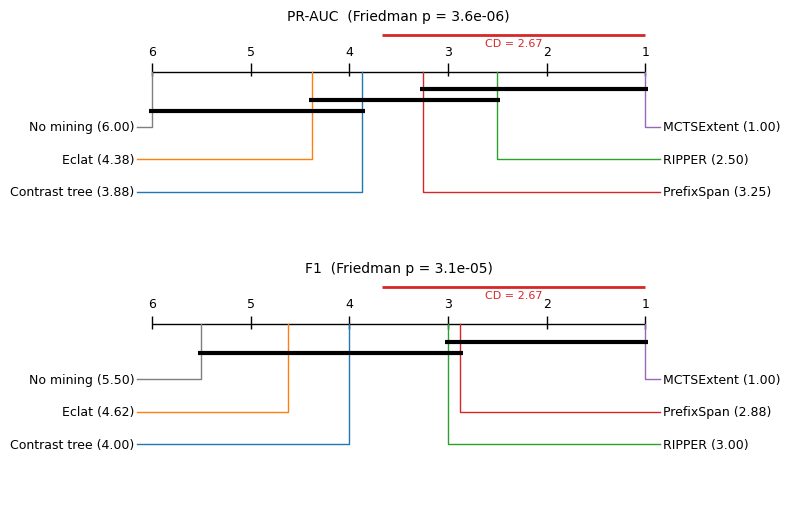

In [10]:
def cd_cliques(ranks: dict[str, float], cd: float) -> list[list[str]]:
    # Maximal groups of arms (in rank order) whose rank span is below CD.
    order = sorted(ranks, key=ranks.get)
    cliques = []
    for i in range(len(order)):
        j = i
        while j + 1 < len(order) and ranks[order[j + 1]] - ranks[order[i]] < cd:
            j += 1
        grp = order[i:j + 1]
        if len(grp) > 1 and not any(set(grp) <= set(c) for c in cliques):
            cliques.append(grp)
    return cliques


def cd_diagram(s: dict, ax) -> None:
    ranks, cd, k = s["avg_rank"], s["nemenyi_cd"], s["n_arms"]
    ax.set_xlim(k + 0.2, 0.8)  # rank 1 on the right
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.hlines(0.8, 1, k, color="k", lw=1)
    for r in range(1, k + 1):
        ax.vlines(r, 0.78, 0.84, color="k", lw=1)
        ax.text(r, 0.88, str(r), ha="center", fontsize=9)
    ax.hlines(0.97, 1, 1 + cd, color="tab:red", lw=2)
    ax.text(1 + cd / 2, 0.92, f"CD = {cd:.2f}", ha="center", fontsize=8, color="tab:red")
    order = sorted(ranks, key=ranks.get)
    half = (len(order) + 1) // 2
    for i, a in enumerate(order):
        right = i < half  # best arms labelled on the right
        y = 0.55 - 0.15 * (i if right else len(order) - 1 - i)
        xe = 0.85 if right else k + 0.15
        ax.plot([ranks[a], ranks[a], xe], [0.8, y, y], color=COLOR[a], lw=1)
        ax.text(xe + (-0.03 if right else 0.03), y, f"{LABEL[a]} ({ranks[a]:.2f})", va="center",
                ha="left" if right else "right", fontsize=9)
    for n, grp in enumerate(cd_cliques(ranks, cd)):
        lo, hi = min(ranks[a] for a in grp), max(ranks[a] for a in grp)
        ax.hlines(0.72 - 0.05 * n, lo - 0.03, hi + 0.03, color="k", lw=3)
    ax.set_title(f"{s['metric'].upper().replace('_', '-')}  (Friedman p = {s['friedman_p']:.2g})", fontsize=10)



fig, axes = plt.subplots(2, 1, figsize=(8, 5.2))
for ax, s in zip(axes, stats.values()):
    cd_diagram(s, ax)
plt.tight_layout()

## §4 The paper's contrasts

Paired over the 8 folds (seed-averaged PR-AUC): mean Δ (B − A), folds where B beats A, and a Wilcoxon signed-rank
p-value (exact, two-sided; with 8 folds the smallest possible p is 0.0078).

- **Label after vs. during the search:** Eclat → contrast tree (atemporal), PrefixSpan → MCTSExtent (temporal).
- **Two-step patterns vs. learning a rule set directly:** contrast tree → RIPPER.
- **Atemporal vs. temporal** (both frequency-based, only order differs): Eclat → PrefixSpan.

In [11]:
CONTRASTS = [
    ("label after → during (atemporal)", "eclat", "contrast_tree"),
    ("label after → during (temporal)", "prefixspan", "mctsextent"),
    ("two-step → rule set", "contrast_tree", "ripper"),
    ("atemporal → temporal", "eclat", "prefixspan"),
]


def paired(metric: str) -> pd.DataFrame:
    d = means.pivot(index="step_i", columns="arm", values=metric)
    rows = []
    for name, a, b in CONTRASTS:
        diff = d[b] - d[a]
        rows.append({
            "contrast": name, "A": LABEL[a], "B": LABEL[b], "metric": metric,
            "mean A": d[a].mean(), "mean B": d[b].mean(), "mean Δ (B−A)": diff.mean(),
            "B better (folds)": f"{int((diff > 0).sum())}/{len(diff)}",
            "Wilcoxon p": sps.wilcoxon(d[b], d[a]).pvalue if (diff != 0).any() else np.nan,
        })
    return pd.DataFrame(rows)


contrasts = pd.concat([paired("pr_auc"), paired("f1")], ignore_index=True)
contrasts.round(4)

,contrast,A,B,metric,mean A,mean B,mean Δ (B−A),B better (folds),Wilcoxon p
0,label after → during (atemporal),Eclat,Contrast tree,pr_auc,0.1400,0.1468,0.0068,6/8,0.1484
1,label after → during (temporal),PrefixSpan,MCTSExtent,pr_auc,0.1628,0.3080,0.1452,8/8,0.0078
2,two-step → rule set,Contrast tree,RIPPER,pr_auc,0.1468,0.1770,0.0302,8/8,0.0078
3,atemporal → temporal,Eclat,PrefixSpan,pr_auc,0.1400,0.1628,0.0227,5/8,0.3125
4,label after → during (atemporal),Eclat,Contrast tree,f1,0.0791,0.0789,-0.0002,6/8,0.2500
5,label after → during (temporal),PrefixSpan,MCTSExtent,f1,0.0984,0.1390,0.0407,8/8,0.0078
6,two-step → rule set,Contrast tree,RIPPER,f1,0.0789,0.0840,0.0051,7/8,0.0547
7,atemporal → temporal,Eclat,PrefixSpan,f1,0.0791,0.0984,0.0193,6/8,0.0547


In [12]:
print(to_booktabs(
    contrasts[contrasts["metric"] == "pr_auc"].drop(columns="metric"),
    caption="AIT-ADS: the paper's contrasts, paired over 8 leave-one-scenario-out folds (PR-AUC).",
    label="tab:mining-contrasts-ait-ads",
))

\begin{table}[t]
\centering
\caption{AIT-ADS: the paper's contrasts, paired over 8 leave-one-scenario-out folds (PR-AUC).}
\label{tab:mining-contrasts-ait-ads}
\begin{tabular}{lllrrrlr}
\toprule
contrast & A & B & mean A & mean B & mean Δ (B−A) & B better (folds) & Wilcoxon p \\
\midrule
label after → during (atemporal) & Eclat & Contrast tree & 0.140 & 0.147 & 0.007 & 6/8 & 0.148 \\
label after → during (temporal) & PrefixSpan & MCTSExtent & 0.163 & 0.308 & 0.145 & 8/8 & 0.008 \\
two-step → rule set & Contrast tree & RIPPER & 0.147 & 0.177 & 0.030 & 8/8 & 0.008 \\
atemporal → temporal & Eclat & PrefixSpan & 0.140 & 0.163 & 0.023 & 5/8 & 0.312 \\
\bottomrule
\end{tabular}
\end{table}



## §5 Seed noise

Std over seeds within a fold, averaged over folds. Eclat, the contrast tree and PrefixSpan are mined once per fold,
so their spread is the RF seed only; RIPPER and MCTSExtent are re-mined per seed.

In [13]:
seed_sd = (per_step.groupby(["arm", "step_i"])[["pr_auc", "f1", "n_symbolic"]].std()
           .groupby("arm").mean().reindex(ARMS))
seed_sd.columns = [f"{c} seed-sd" for c in seed_sd.columns]
seed_sd

,pr_auc seed-sd,f1 seed-sd,n_symbolic seed-sd
arm,,,
mctsextent,0.014372,0.007818,0.396655
prefixspan,0.003947,0.001099,0.000000
ripper,0.012119,0.007243,12.399649
contrast_tree,0.003407,0.001395,0.000000
eclat,0.002918,0.001479,0.000000
none,0.002425,0.001268,0.000000


## §6 What the features look like

Seed 0 for the stochastic miners. Attack- vs. benign-leaning features per fold, and the number of conditions
(steps for sequences, items for itemsets and rules).

In [14]:
f0 = features[features["mining_seed"] == features.groupby("arm")["mining_seed"].transform("min")]
lean = (f0.groupby(["arm", "step_i", "source_label"]).size().unstack(fill_value=0)
        .groupby("arm").mean().reindex(METHODS))
lean.columns = [f"{c} / fold" for c in lean.columns]
cond = (f0.groupby(["arm", "n_conditions"]).size().unstack(fill_value=0)
        .pipe(lambda d: d.div(d.sum(axis=1), axis=0)).reindex(METHODS))
cond.columns = [f"{c} cond." for c in cond.columns]
lean.join(cond).round(3)

,attack / fold,benign / fold,1 cond.,2 cond.,3 cond.,4 cond.,5 cond.,6 cond.,7 cond.,8 cond.,9 cond.,10 cond.,11 cond.,12 cond.,13 cond.,16 cond.
arm,,,,,,,,,,,,,,,,
mctsextent,23.125,25.000,0.543,0.151,0.130,0.036,0.023,0.008,0.005,0.005,0.018,0.052,0.016,0.008,0.003,0.003
prefixspan,30.750,29.250,0.000,0.029,0.971,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ripper,17.875,18.875,0.027,0.112,0.228,0.194,0.224,0.119,0.044,0.034,0.010,0.007,0.000,0.000,0.000,0.000
contrast_tree,17.250,3.500,0.337,0.343,0.102,0.217,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
eclat,6.375,6.750,0.019,0.133,0.848,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


### Agreement between folds

LOSO has no consecutive steps, so stability over time isn't defined. Instead: how many of the 8 folds keep each
condition (folds differ in one training scenario out of 8), and the mean pairwise Jaccard of the folds' condition
sets per method.

In [15]:
sets = f0.groupby(["arm", "step_i"])["condition"].apply(set)
agree = {}
for a in METHODS:
    s = sets.loc[a]
    pairs = [len(s[i] & s[j]) / len(s[i] | s[j]) for i, j in combinations(s.index, 2) if s[i] | s[j]]
    agree[LABEL[a]] = np.mean(pairs) if pairs else np.nan
pd.Series(agree, name="mean pairwise Jaccard of kept conditions between folds").round(3)

MCTSExtent       0.031
PrefixSpan       0.497
RIPPER           0.055
Contrast tree    0.451
Eclat            0.645
Name: mean pairwise Jaccard of kept conditions between folds, dtype: float64

In [16]:
TOP = 6
persist = (f0.groupby(["arm", "condition", "source_label"])["step_i"].nunique()
           .rename("folds").reset_index().sort_values(["arm", "folds"], ascending=[True, False]))
for a in METHODS:
    print(f"\n== {LABEL[a]} ==")
    top = persist[persist["arm"] == a].head(TOP)
    for _, r in top.iterrows():
        c = r["condition"] if len(r["condition"]) <= 110 else r["condition"][:107] + "..."
        print(f"  {r['folds']} folds  {r['source_label']:<7} {c}")


== MCTSExtent ==
  6 folds  attack  short_src:A
  5 folds  attack  short:A-Acc-Chr2 & short_cat:A-Acc & short_family:apache_access & short_src:A & sig_family:apache_access & ...
  5 folds  attack  short:S-Flw-Nmp & short:W-All-Evt & short_cat:S-Flw & short_cat:W-All & short_family:ids & short_family:net...
  5 folds  benign  sig_family:dns
  3 folds  benign  short:S-Dns-Qry3 & short:S-Tls-Hnd & short:S-Tls-Rec & short:W-All-Evt & short_cat:S-Dns & short_cat:S-Tls ...
  3 folds  benign  short:S-Dns-Qry3 & short:W-All-Evt & short_cat:S-Dns & short_cat:W-All & short_family:dns & short_family:id...

== PrefixSpan ==
  8 folds  attack  short:A-All-Evt -> short_src:W -> short_src:W
  8 folds  benign  short:W-All-Mul1 -> short:W-All-Evt -> short:W-All-Mul1
  8 folds  benign  short_family:dns -> short_family:dns -> short_src:W
  8 folds  attack  short_src:A -> short_src:W -> short_src:W
  8 folds  attack  short_src:W -> short:A-All-Evt -> short_src:W
  8 folds  attack  short_src:W -> short_sr

### Which token levels each method leans on

Share of a method's kept conditions that mention each token level (T2 arm): the full code (`short`, `sig`), the
coarse levels (`short_src`, `short_cat`, `short_family`, `sig_family`) and the other fields (host, alert count, ...).

In [17]:
def token_levels(cond: str) -> set[str]:
    out = set()
    for tok in re.split(r" -> | & | ∧ ", cond):
        tok = tok.strip().removeprefix("NOT_")
        out.add(re.split(r":|<=|>=|<|>|=|_gt_|_le_", tok)[0])
    return out


lv = f0.assign(level=f0["condition"].map(token_levels)).explode("level")
level_share = (lv.groupby(["arm", "level"]).size().div(f0.groupby("arm").size(), level="arm")
               .unstack("arm").reindex(columns=METHODS).fillna(0))
level_share.sort_values("mctsextent", ascending=False).round(3).head(15)

arm,mctsextent,prefixspan,ripper,contrast_tree,eclat
level,,,,,
short,0.774,0.458,0.517,0.084,0.076
short_cat,0.751,0.310,0.320,0.096,0.352
short_src,0.751,0.742,0.357,0.271,0.362
short_family,0.738,0.142,0.048,0.139,0.610
sig_family,0.613,0.471,0.367,0.319,0.343
alert_count,0.000,0.000,0.541,0.265,0.114
host,0.000,0.000,0.854,0.669,0.448
sig,0.000,0.000,0.282,0.235,0.371


## §7 Cost vs. score

Mining time per seed (whole mine → gate → dedupe step, mean over folds) against PR-AUC. Log scale on time.

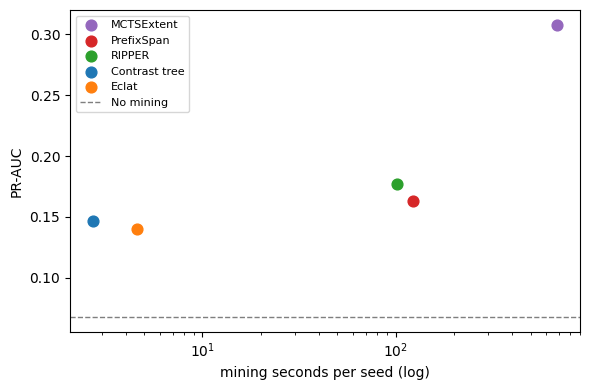

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
for a in METHODS:
    ax.scatter(main.loc[a, "Mine s"], main.loc[a, "PR-AUC"], s=60, color=COLOR[a], label=LABEL[a])
ax.axhline(main.loc["none", "PR-AUC"], color=COLOR["none"], ls="--", lw=1, label="No mining")
ax.set_xscale("log"); ax.set_xlabel("mining seconds per seed (log)"); ax.set_ylabel("PR-AUC")
ax.legend(fontsize=8); plt.tight_layout()

## §8 Label-noise context

Precision and false positives per day per held-out scenario: every arm flags many benign groups, because the same
alert names occur as attacks inside attack windows and as benign outside them.

In [19]:
ctx = (means.pivot(index="step_i", columns="arm", values="fp_per_day").rename(index=FOLD)[ARMS].round(0)
       .join(folds.set_index("scenario")["test_attack_rate"].round(3)))
ctx.index.name, ctx.columns.name = "held-out", None
ctx

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none,test_attack_rate
held-out,,,,,,,
fox,226.0,259.0,314.0,328.0,332.0,382.0,0.044
harrison,189.0,233.0,383.0,472.0,482.0,548.0,0.045
russellmitchell,250.0,295.0,354.0,350.0,342.0,364.0,0.044
santos,337.0,343.0,626.0,660.0,572.0,688.0,0.021
shaw,197.0,241.0,319.0,326.0,312.0,356.0,0.015
wardbeck,265.0,328.0,411.0,410.0,417.0,479.0,0.020
wheeler,297.0,339.0,777.0,799.0,791.0,1092.0,0.013
wilson,301.0,364.0,524.0,594.0,538.0,627.0,0.029


## Summary

Fill in after reading the run:
- **Mining helps** with every method (§2)? Which beat `none` significantly (§3)?
- **The contrasts** (§4): label during vs. after for sequences and for itemsets; rule set vs. two-step; order.
- **Feature character and cost** (§1, §6, §7).
- **Compared with CSCAS** (notebook 06): where does the contrast tree land on each dataset, and why?